# Superconductor Critical Temperature Prediction

Superconductors only work below a **critical temperature** — and finding a material with a high one normally takes years of lab experiments. This dataset turns 21,263 known compounds into numbers (element counts plus thermal / valence / atomic-mass statistics of their ingredients). Predict the critical temperature from the recipe alone.


In [1]:
import io, urllib.request, zipfile, gzip
import numpy as np
import pandas as pd

def download(url):
    req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(req, timeout=180) as r:
        return r.read()
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score, mean_absolute_error

raw = download('https://archive.ics.uci.edu/static/public/464/superconductivty+data.zip')
zf = zipfile.ZipFile(io.BytesIO(raw))
df = pd.read_csv(io.BytesIO(zf.read('train.csv')))
print(df.shape)
df.head(3)

(21263, 82)


,number_of_elements,mean_atomic_mass,wtd_mean_atomic_mass,gmean_atomic_mass,wtd_gmean_atomic_mass,entropy_atomic_mass,wtd_entropy_atomic_mass,range_atomic_mass,wtd_range_atomic_mass,std_atomic_mass,...,wtd_mean_Valence,gmean_Valence,wtd_gmean_Valence,entropy_Valence,wtd_entropy_Valence,range_Valence,wtd_range_Valence,std_Valence,wtd_std_Valence,critical_temp
0,4,88.944468,57.862692,66.361592,36.116612,1.181795,1.062396,122.90607,31.794921,51.968828,...,2.257143,2.213364,2.219783,1.368922,1.066221,1,1.085714,0.433013,0.437059,29.0
1,5,92.729214,58.518416,73.132787,36.396602,1.449309,1.057755,122.90607,36.161939,47.094633,...,2.257143,1.888175,2.210679,1.557113,1.047221,2,1.128571,0.632456,0.468606,26.0
2,4,88.944468,57.885242,66.361592,36.122509,1.181795,0.975980,122.90607,35.741099,51.968828,...,2.271429,2.213364,2.232679,1.368922,1.029175,1,1.114286,0.433013,0.444697,19.0


In [2]:
X = df.drop(columns=['critical_temp']); y = df['critical_temp']
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=42)
rf = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1).fit(Xtr, ytr)
lin = make_pipeline(StandardScaler(), LinearRegression()).fit(Xtr, ytr)
for name_m, m in [('Random Forest', rf), ('Linear', lin)]:
    p = m.predict(Xte)
    print(f'{name_m:15s} R2 {r2_score(yte, p):.3f}  MAE {mean_absolute_error(yte, p):.2f} K')

Random Forest   R2 0.925  MAE 5.18 K
Linear          R2 0.728  MAE 13.39 K


range_ThermalConductivity          0.539210
wtd_gmean_ThermalConductivity      0.125991
std_atomic_mass                    0.024296
wtd_gmean_Valence                  0.021255
wtd_entropy_ThermalConductivity    0.012327
mean_Density                       0.011045
wtd_mean_Valence                   0.010680
gmean_ElectronAffinity             0.010348
wtd_mean_ThermalConductivity       0.010072
wtd_std_ElectronAffinity           0.009702
std_Density                        0.009356
wtd_std_Valence                    0.008924
dtype: float64


<Axes: title={'center': 'Which material features predict critical temperature?'}>

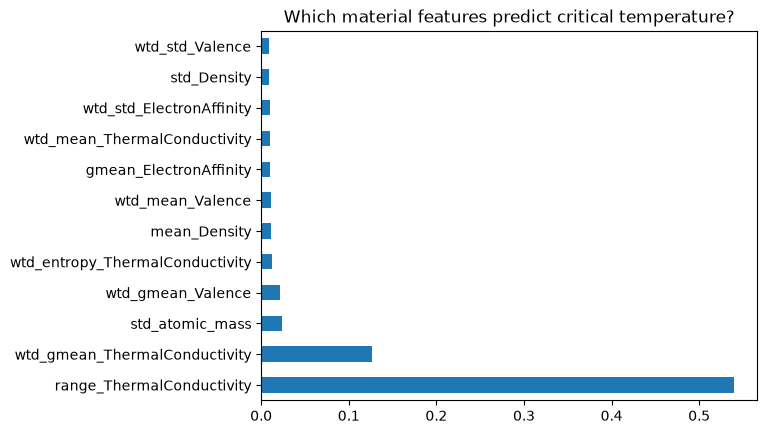

In [3]:
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print(imp.head(12))
imp.head(12).plot(kind='barh', title='Which material features predict critical temperature?')